<a href="https://colab.research.google.com/github/pusalaspreetham-code/amazon-review-analyzer/blob/main/model/amazon_sentiment_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load saved model

In [4]:
import joblib
import os

#model_path = "/content/logistic_regression_model.pkl"

model_path="/content/weighted_soft_voting_model.pkl"
print("Model exists:", os.path.exists(model_path))

saved_model = joblib.load(model_path)

print("Model loaded successfully!")

Model exists: True
Model loaded successfully!


loading amazon dataset


In [5]:
import pandas as pd

df_original = pd.read_csv("/content/amazon_reviews_cleaned.csv")

print("Original Dataset Shape:", df_original.shape)
print("\nColumns:")
print(df_original.columns.tolist())

df_original.head()

Original Dataset Shape: (11462, 20)

Columns:
['review_id', 'product_id', 'product_name', 'category', 'product_url', 'price', 'original_price', 'product_rating', 'total_product_reviews', 'five_star_review_count', 'four_star_review_count', 'three_star_review_count', 'two_star_review_count', 'one_star_review_count', 'review_title', 'review_text', 'review_rating', 'helpful_votes', 'review_age', 'discount_percentage']


,review_id,product_id,product_name,category,product_url,price,original_price,product_rating,total_product_reviews,five_star_review_count,four_star_review_count,three_star_review_count,two_star_review_count,one_star_review_count,review_title,review_text,review_rating,helpful_votes,review_age,discount_percentage
0,RKSVOZF894JFW,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Best shower gel,Love this shower gel feels fresh in every shower,5.0,0,1 year ago,61.78
1,R1ZNY7WGCQTRY4,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Doubt its original as quality and scent not same,Quality deteriorated scent is almost negligibl...,2.0,2,3 years ago,61.78
2,RK2R8UNJ28858,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Average product,Soap remains on body even after thorough wash,3.0,1,3 years ago,61.78
3,R1PSRBJB5CR0XE,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Awesome fragrance,Fragrance is really nice and refreshing also e...,4.0,1,2 years ago,61.78
4,R3FK9S0MB6SRS4,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,The nozzle was open so liquid soap leaked,The nozzle was not correctly and liquid soap w...,1.0,1,2 years ago,61.78


Preparing prediction text

In [6]:
# Combine review title and review content
df_original["prediction_text"] = (
    df_original["review_title"].astype(str) + " " +
    df_original["review_text"].astype(str)
).str.strip()


print("Total reviews:", len(df_original))

Total reviews: 11462


Predict sentiment

In [7]:
# Generate sentiment predictions
predictions = saved_model.predict(
    df_original["prediction_text"]
)

# Add predictions to original dataset
df_original["predicted_sentiment"] = predictions

print("Sentiment prediction completed!")
print("Total predictions:", len(predictions))

print("\nSample Predictions:")
display(
    df_original[
        ["review_title", "review_text", "predicted_sentiment"]
    ].head(10)
)

Sentiment prediction completed!
Total predictions: 11462

Sample Predictions:


,review_title,review_text,predicted_sentiment
0,Best shower gel,Love this shower gel feels fresh in every shower,positive
1,Doubt its original as quality and scent not same,Quality deteriorated scent is almost negligibl...,negative
2,Average product,Soap remains on body even after thorough wash,negative
3,Awesome fragrance,Fragrance is really nice and refreshing also e...,positive
4,The nozzle was open so liquid soap leaked,The nozzle was not correctly and liquid soap w...,negative
5,A good Shower Gel,I expected a predominance of citrus notes. A g...,positive
6,Old stock,Received old stock as the manufacturing date w...,negative
7,Good fragrance but....,The smell is great but it does not feel fresh ...,neutral
8,It's ok,It's ok,neutral
9,Excellent product value for money Love you Amazon,I am very happy lo🫶🫶🫶 ❤️❤️❤️ Amazon,positive


Genrating prediction probabilities

In [8]:
# Generate probabilities
probabilities = saved_model.predict_proba(
    df_original["prediction_text"]
)

# Store the highest probability
df_original["prediction_probability"] = (
    probabilities.max(axis=1) * 100
)

print("Prediction probabilities generated!")

display(
    df_original[
        ["review_title", "predicted_sentiment", "prediction_probability"]
    ].head(10)
)

Prediction probabilities generated!


,review_title,predicted_sentiment,prediction_probability
0,Best shower gel,positive,84.007243
1,Doubt its original as quality and scent not same,negative,46.325743
2,Average product,negative,61.086458
3,Awesome fragrance,positive,73.287229
4,The nozzle was open so liquid soap leaked,negative,70.388771
5,A good Shower Gel,positive,65.274856
6,Old stock,negative,52.073621
7,Good fragrance but....,neutral,49.753782
8,It's ok,neutral,60.602695
9,Excellent product value for money Love you Amazon,positive,92.672517


Analysing the predictions

In [9]:
sentiment_counts = df_original["predicted_sentiment"].value_counts()

print("Sentiment Distribution:")
print(sentiment_counts)

Sentiment Distribution:
predicted_sentiment
negative    4866
positive    4703
neutral     1893
Name: count, dtype: int64


Inspecting the predictions

In [10]:
display(
    df_original[
        [
            "review_title",
            "review_text",
            "predicted_sentiment",
            "prediction_probability"
        ]
    ].sample(15, random_state=42)
)

,review_title,review_text,predicted_sentiment,prediction_probability
9145,Fast Charging cable,This product package is smaller and good quali...,neutral,43.943507
304,"Dell laptop in 48K,A good buy with good support.",The dell laptop body and built is good and mad...,neutral,44.172789
5156,skin soft and protected,very nice i used twice a day its too good to use,positive,87.406465
8009,Charger Not Working,I purchased the Samsung Galaxy S25 Ultra 5G AI...,negative,58.542246
6161,Good for nthng,"Not even good for drying out, takes too much t...",positive,51.320145
4032,Price range,Worth at this price,positive,78.875569
5882,Problem with back to back printing,This does not support auto back to back printi...,negative,44.264124
1683,Great Fast Charger with Excellent Performance,Fast charging and works perfectly with my Moto...,positive,79.559936
10041,Best value for money smartphone in this price,Redmi A7 Pro 5G 4GB/128GB – Great Phone!I rece...,positive,72.122338
5143,Defective product,I ordered this product and got the product sea...,negative,89.136671


In [11]:
display(
    df_original.sort_values(
        by="prediction_probability",
        ascending=True
    )[
        [
            "review_title",
            "review_text",
            "predicted_sentiment",
            "prediction_probability"
        ]
    ].head(10)
)

,review_title,review_text,predicted_sentiment,prediction_probability
8492,scam,Amazon scammed meThey took nearly 1450 rupees ...,neutral,33.482913
3147,Tight keys,The keys are hard to press. I'm owing it more ...,positive,33.532594
4770,Doesn't woek,"Texture is light,fragrance free,non greasy but...",positive,33.640617
1592,Okay product at this price,Plastic jar.. okay not that great built,positive,33.773409
7178,😔,I got melasma but iam allergic to vit c serum....,positive,33.814666
4206,Not for me,"Well it doesn't suit me, I got rashes after us...",negative,33.840166
9731,Okay,It's touch sensors need improvement,negative,33.953450
11436,No TV setup,It doesn’t work with TV if you want read data ...,neutral,34.024616
8498,CHARGING ADAPTOR,As charger adapter work nicely fast but it als...,negative,34.139528
593,.,Value for money. Charger is not good,positive,34.140220


Confidence distubution

In [12]:
print("Average prediction confidence:",df_original["prediction_probability"].mean())

print("\nConfidence distribution:")

print(
    df_original["prediction_probability"].describe()
)

Average prediction confidence: 65.29636677380576

Confidence distribution:
count    11462.000000
mean        65.296367
std         15.961808
min         33.482913
25%         51.224866
50%         65.136349
75%         79.274737
max         95.794169
Name: prediction_probability, dtype: float64


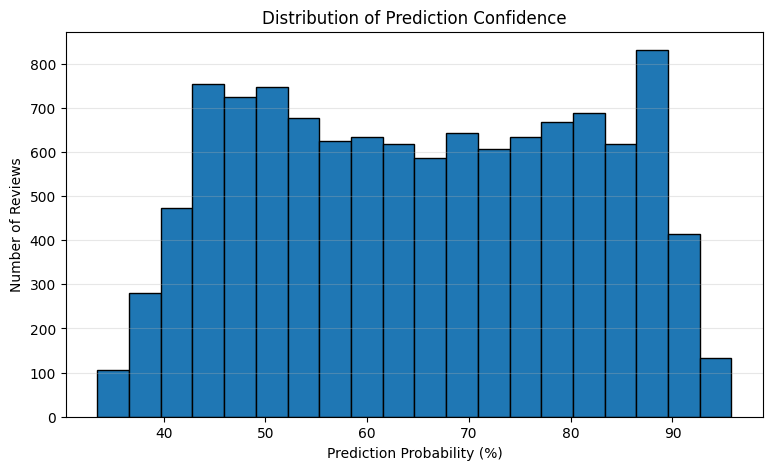

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df_original["prediction_probability"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Prediction Probability (%)")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Prediction Confidence")
plt.grid(axis="y", alpha=0.3)
plt.show()

Categroise confidence

In [15]:
# Categorize prediction confidence
def categorize_confidence(probability):
    if probability >= 75:
        return "High"
    elif probability >= 50:
        return "Medium"
    else:
        return "Low"


df_original["confidence_level"] = (df_original["prediction_probability"].apply(categorize_confidence))

# Separate high-confidence predictions
high_confidence_reviews = df_original[df_original["confidence_level"] == "High"].copy()
medium_confidence_reviews = df_original[df_original["confidence_level"] == "Medium"].copy()
low_confidence_reviews = df_original[df_original["confidence_level"] == "Low"].copy()
print("Total reviews:", len(df_original))
print("High-confidence reviews:",len(high_confidence_reviews))
print("Medium-confidence reviews:",len(medium_confidence_reviews))
print("Low-confidence reviews:",len(low_confidence_reviews))
print("Percentage of high-confidence reviews:",round(len(high_confidence_reviews) / len(df_original) * 100, 2),"%")

Total reviews: 11462
High-confidence reviews: 3787
Medium-confidence reviews: 5105
Low-confidence reviews: 2570
Percentage of high-confidence reviews: 33.04 %


In [16]:
  high_confidence_sentiment = (
    high_confidence_reviews["predicted_sentiment"]
    .value_counts()
    .reindex(["positive", "negative", "neutral"], fill_value=0)
)

print("High-confidence sentiment distribution:")
print(high_confidence_sentiment)

print("\nPercentage distribution:")

print((high_confidence_sentiment/len(high_confidence_reviews) * 100).round(2))

High-confidence sentiment distribution:
predicted_sentiment
positive    2261
negative    1430
neutral       96
Name: count, dtype: int64

Percentage distribution:
predicted_sentiment
positive    59.70
negative    37.76
neutral      2.53
Name: count, dtype: float64


Save the cell

In [20]:
# Save the complete dataset with predictions
output_path = "amazon_sentiment_predictions.csv"

df_original.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File path:", output_path)
print("Total rows:", len(df_original))
print("Total columns:", len(df_original.columns))

Dataset saved successfully!
File path: amazon_sentiment_predictions.csv
Total rows: 11462
Total columns: 24
